In [53]:
import requests
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config #config.py file

In [54]:
API_KEY = config.api_key
print("API key loaded successfully")

API key loaded successfully


In [55]:
api_url = 'https://data.nasdaq.com/api/v3/datatables/MER/F1.json' # using MER/F1 data table

In [56]:
parameters = {
    'api_key': API_KEY,
    'qopts.per_page': 10000
}

json_data = requests.get(api_url, params=parameters).json() #


In [57]:
data = json_data['datatable']['data']

columns = [col['name'] for col in json_data['datatable']['columns']]

df = pd.DataFrame(data, columns=columns)
df['reportdate'] = pd.to_datetime(df['reportdate'], errors='coerce')
df.head()

,compnumber,reportid,mapcode,amount,reportdate,reporttype,auditorstatus,currency,consolidated,longname,...,city,statecode,country,zipcode,phonenumber,faxnumber,website,fye,indicator,statement
0,2438,1868192544,-1802,10.481948,2011-06-30,Q2,U,EUR,True,Deutsche Bank AG,...,Frankfurt am Main,None,DEU,60325,(49) 69 910 00,(49) 69 910 34 225,www.db.com,2024-12-31,Accrued Expenses Turnover,Derived
1,2438,1868216112,-1802,8.161754,2011-09-30,Q3,U,EUR,True,Deutsche Bank AG,...,Frankfurt am Main,None,DEU,60325,(49) 69 910 00,(49) 69 910 34 225,www.db.com,2024-12-31,Accrued Expenses Turnover,Derived
2,2438,1885063456,-1802,10.788213,2012-06-30,Q2,U,EUR,True,Deutsche Bank AG,...,Frankfurt am Main,None,DEU,60325,(49) 69 910 00,(49) 69 910 34 225,www.db.com,2024-12-31,Accrued Expenses Turnover,Derived
3,2438,1885087024,-1802,9.437545,2012-09-30,Q3,U,EUR,True,Deutsche Bank AG,...,Frankfurt am Main,None,DEU,60325,(49) 69 910 00,(49) 69 910 34 225,www.db.com,2024-12-31,Accrued Expenses Turnover,Derived
4,2438,1901934112,-1802,8.755041,2013-06-30,Q2,U,EUR,True,Deutsche Bank AG,...,Frankfurt am Main,None,DEU,60325,(49) 69 910 00,(49) 69 910 34 225,www.db.com,2024-12-31,Accrued Expenses Turnover,Derived


In [58]:
necessary_columns = ['reportid','reportdate','reporttype','amount','longname','country','region','indicator','statement']
df = df[necessary_columns]
df.head()

,reportid,reportdate,reporttype,amount,longname,country,region,indicator,statement
0,1868192544,2011-06-30,Q2,10.481948,Deutsche Bank AG,DEU,Europe,Accrued Expenses Turnover,Derived
1,1868216112,2011-09-30,Q3,8.161754,Deutsche Bank AG,DEU,Europe,Accrued Expenses Turnover,Derived
2,1885063456,2012-06-30,Q2,10.788213,Deutsche Bank AG,DEU,Europe,Accrued Expenses Turnover,Derived
3,1885087024,2012-09-30,Q3,9.437545,Deutsche Bank AG,DEU,Europe,Accrued Expenses Turnover,Derived
4,1901934112,2013-06-30,Q2,8.755041,Deutsche Bank AG,DEU,Europe,Accrued Expenses Turnover,Derived


In [59]:
country_mapping = {
    'JPN': 'Japan',
    'DEU': 'Germany',
    'USA': 'United States',
    'CYM': 'Cayman Islands',
    'BHS': 'Bahamas',
    'IRL': 'Ireland',
    'IND': 'India',
    'AUS': 'Australia',
    'CAN': 'Canada',
    'BRA': 'Brazil',
    'IDN': 'Indonesia',
    'ISR': 'Israel',
    'FIN': 'Finland',
    'CHE': 'Switzerland',
    'KOR': 'South Korea',
    'GBR': 'United Kingdom',
    'FRA': 'France',
    'CHL': 'Chile',
    'BEL': 'Belgium',
    'ITA': 'Italy',
    'HKG': 'Hong Kong',
    'DNK': 'Denmark',
    'ESP': 'Spain'
}

df['country'] = df['country'].replace(country_mapping)


In [60]:
df.columns=['report_id','report_date','report_type','amount','company_name','country','region','indicator','statement'] 
df.head()

,report_id,report_date,report_type,amount,company_name,country,region,indicator,statement
0,1868192544,2011-06-30,Q2,10.481948,Deutsche Bank AG,Germany,Europe,Accrued Expenses Turnover,Derived
1,1868216112,2011-09-30,Q3,8.161754,Deutsche Bank AG,Germany,Europe,Accrued Expenses Turnover,Derived
2,1885063456,2012-06-30,Q2,10.788213,Deutsche Bank AG,Germany,Europe,Accrued Expenses Turnover,Derived
3,1885087024,2012-09-30,Q3,9.437545,Deutsche Bank AG,Germany,Europe,Accrued Expenses Turnover,Derived
4,1901934112,2013-06-30,Q2,8.755041,Deutsche Bank AG,Germany,Europe,Accrued Expenses Turnover,Derived


In [61]:
filtered_df=df[df['indicator']=='EBITDA Margin'].copy()
filtered_df.head()

,report_id,report_date,report_type,amount,company_name,country,region,indicator,statement
662,1868192512,2011-06-30,A,-1979.328191,Immutep Ltd,Australia,Asia Pacific,EBITDA Margin,Derived
768,1918804736,2014-06-30,A,-86142.858937,Immutep Ltd,Australia,Asia Pacific,EBITDA Margin,Derived
817,1935675392,2015-06-30,A,-19363.385060,Immutep Ltd,Australia,Asia Pacific,EBITDA Margin,Derived
845,1851368960,2010-12-31,A,26.841546,Ultrapetrol (Bahamas) Ltd,Bahamas,Latin America,EBITDA Margin,Derived
889,1851369024,2010-12-31,Q4,14.403761,Ultrapetrol (Bahamas) Ltd,Bahamas,Latin America,EBITDA Margin,Derived


In [62]:
filtered_df.sort_values(by='amount')

,report_id,report_date,report_type,amount,company_name,country,region,indicator,statement
768,1918804736,2014-06-30,A,-86142.858937,Immutep Ltd,Australia,Asia Pacific,EBITDA Margin,Derived
817,1935675392,2015-06-30,A,-19363.385060,Immutep Ltd,Australia,Asia Pacific,EBITDA Margin,Derived
662,1868192512,2011-06-30,A,-1979.328191,Immutep Ltd,Australia,Asia Pacific,EBITDA Margin,Derived
2203,1851368960,2010-12-31,A,-26.841528,China Unicom (Hong Kong) Ltd,Hong Kong,Asia Pacific,EBITDA Margin,Derived
2205,1868239616,2011-12-31,A,-22.854944,China Unicom (Hong Kong) Ltd,Hong Kong,Asia Pacific,EBITDA Margin,Derived
...,...,...,...,...,...,...,...,...,...
2048,1868192544,2011-06-30,Q2,43.551968,BCE Inc,Canada,North America,EBITDA Margin,Derived
2054,1885040144,2012-03-31,Q1,43.756366,BCE Inc,Canada,North America,EBITDA Margin,Derived
2045,1868169232,2011-03-31,Q1,44.872369,BCE Inc,Canada,North America,EBITDA Margin,Derived
2058,1885087024,2012-09-30,Q3,45.624247,BCE Inc,Canada,North America,EBITDA Margin,Derived


In [63]:
filtered_df = filtered_df[filtered_df['company_name'] != 'Immutep Ltd']
filtered_df.describe()

,report_id,report_date,amount
count,2.860000e+02,286,286.000000
mean,1.745579e+09,2013-06-24 20:28:31.888111872,18.194177
min,1.504051e+09,2010-12-31 00:00:00,-26.841528
25%,1.569850e+09,2012-01-15 00:00:00,14.146726
50%,1.859769e+09,2013-06-29 12:00:00,17.296259
75%,1.901952e+09,2014-11-14 18:00:00,26.055693
max,1.952476e+09,2015-12-31 00:00:00,47.410116
std,1.694033e+08,NaN,13.189965


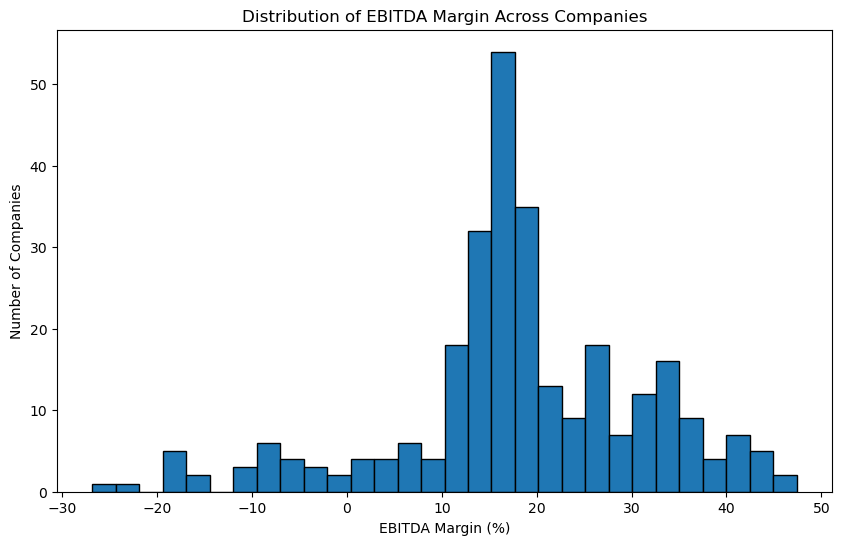

In [64]:
plt.figure(figsize=(10, 6))
plt.hist(filtered_df['amount'], bins=30, edgecolor='black')
plt.xlabel('EBITDA Margin (%)')
plt.ylabel('Number of Companies')
plt.title('Distribution of EBITDA Margin Across Companies')
plt.show()

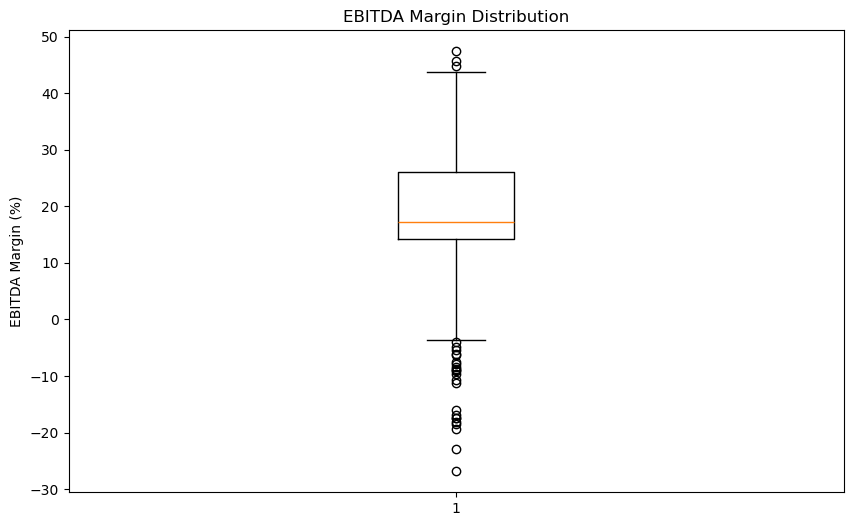

In [65]:
plt.figure(figsize=(10, 6))
plt.boxplot(filtered_df['amount'])
plt.ylabel('EBITDA Margin (%)')
plt.title('EBITDA Margin Distribution')
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

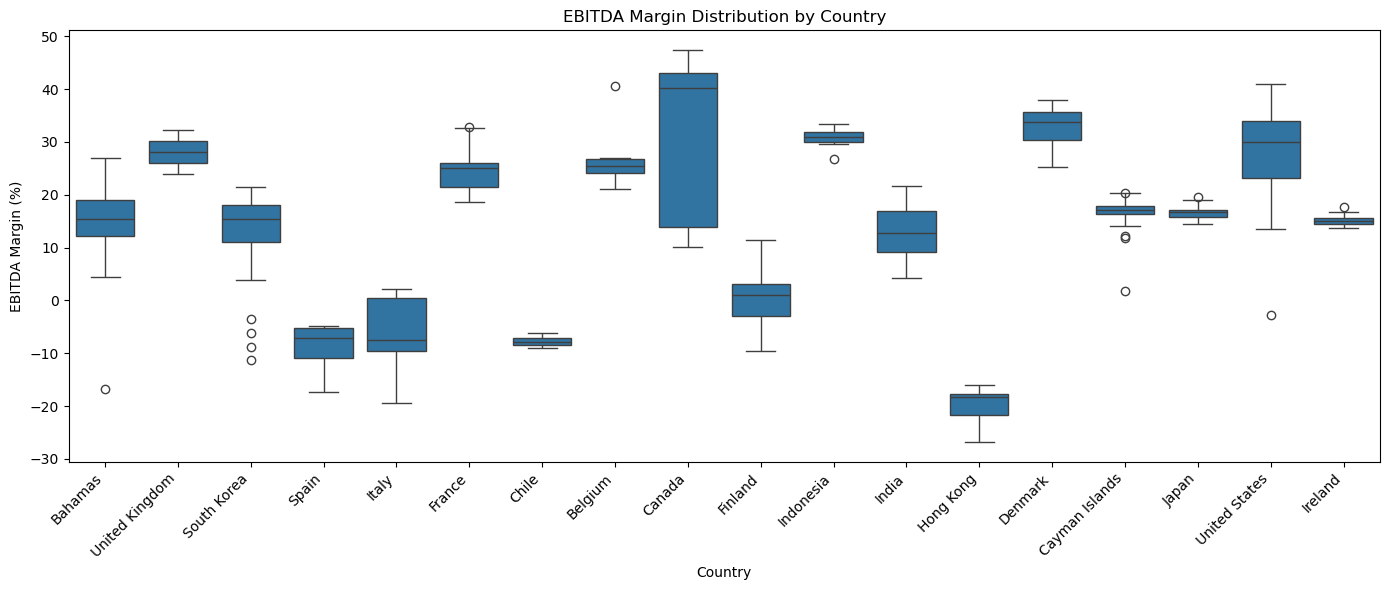

In [66]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=filtered_df, x='country', y='amount')
plt.xlabel('Country')
plt.ylabel('EBITDA Margin (%)')
plt.title('EBITDA Margin Distribution by Country')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show

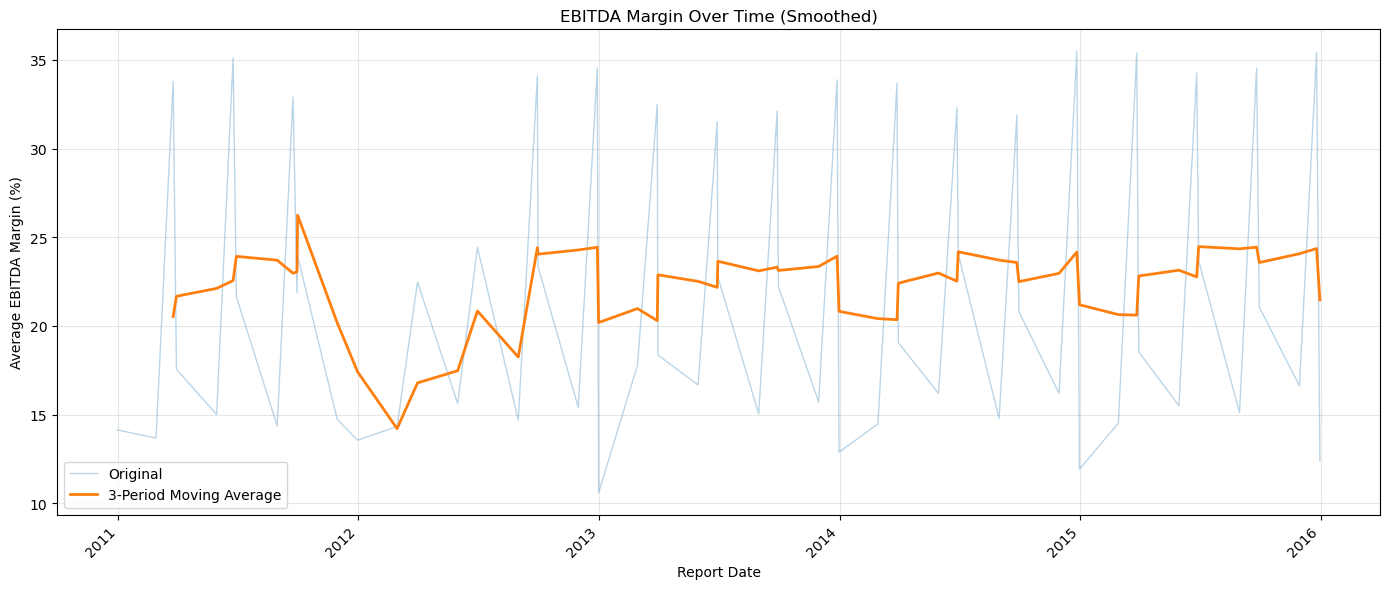

In [67]:
time_trend = filtered_df.groupby('report_date')['amount'].mean()
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(time_trend.index, time_trend.values, alpha=0.3, label='Original', linewidth=1)
smoothed = time_trend.rolling(window=3).mean()
ax.plot(smoothed.index, smoothed.values, label='3-Period Moving Average', linewidth=2)

ax.set_xlabel('Report Date')
ax.set_ylabel('Average EBITDA Margin (%)')
ax.set_title('EBITDA Margin Over Time (Smoothed)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()